In [93]:
import pandas as pd
import xarray as xr
import rioxarray 
import matplotlib.pyplot as plt
import numpy as np
import pystormtracker as pst
from pystormtracker.metrics.compare import compare_tracks, TrackComparisonConfig

from pyproj import Transformer

import cartopy.crs as ccrs
import cartopy.feature as cfeature


from pathlib import Path
import sys
import os

module_dir = (Path.cwd() / ".." / "master_thesis" / "algorithms").resolve()
sys.path.insert(0,str(module_dir))

import importlib

import validation as val
import processing as pro
from configs import *
from plotting import *


import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro) 



<module 'processing' from '/Users/annasophiamaxen/Desktop/PYTHON/master_thesis/algorithms/processing.py'>

In [94]:
tracks_ew = pst.load_tracks('/Users/annasophiamaxen/Desktop/PYTHON/MASTER/19981999_DJF_NH_vo_org_grid.trackjson')
tracks_regrid_3 = pst.load_tracks('/Users/annasophiamaxen/Desktop/PYTHON/MASTER/3_9899_DJF.trackjson')
tracks_regrid_0_5 = pst.load_tracks('/Users/annasophiamaxen/Desktop/PYTHON/MASTER/05_19981999_DJF_NH_vo_org_grid.trackjson')

In [95]:
times = tracks_ew.times.astype('datetime64[ms]')

t_start, t_end = times.min(), times.max()
print(t_start, t_end)

1998-12-01T00:00:00.000 1999-02-28T18:00:00.000


In [96]:
from helpers import wrap_lon

def clip_tracks(tracks):
    """Tracks -> DataFrame -> clip_to_domain -> Tracks."""
    var = tracks.primary_variable
    df = pd.DataFrame({
        "track_id": tracks.point_track_ids(),
        "time": pd.to_datetime(tracks.times, unit="ms"),
        "lat": tracks.lats,
        "lon": wrap_lon(tracks.lons, to="-180"),
        var: tracks.variables[var],
    })
    df = val.clip_to_domain(df, DOMAIN, time_range=(t_start, t_end))
    return val.dataframe_to_tracks(df, variable=var, units=tracks.units[var], mode=tracks.mode)

#tracks_ew = clip_tracks(tracks_ew)
#tracks_regrid_3 = clip_tracks(tracks_regrid_3)
#tracks_regrid_0_5 = clip_tracks(tracks_regrid_0_5)


In [97]:
tracks_0_25, sum_0_25, points_0_25 = pro.postprocess_tracks(tracks_ew, **POSTPROCESS_CONFIG)
tracks_0_5, sum_0_5, points_0_5 = pro.postprocess_tracks(tracks_regrid_0_5, **POSTPROCESS_CONFIG)
tracks_3, sum_3, points_3 = pro.postprocess_tracks(tracks_regrid_3, **POSTPROCESS_CONFIG)

In [98]:
#tracks_0_25 = clip_tracks(tracks_0_25)
#tracks_0_5 = clip_tracks(tracks_0_5)
#tracks_3 = clip_tracks(tracks_3)

In [99]:
points_0_25

,track_id,time,lat,lon,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,object_moment_orientation_degrees,raw_value,vo,step_km,in_region,at_edge
0,1,1998-12-15 00:00:00,-26.50,-21.25,0.0,0.0,0.0,0.0,0.0,0.000019,0.000019,0.000000,False,True
1,1,1998-12-15 06:00:00,-27.00,-22.00,0.0,0.0,0.0,0.0,0.0,0.000021,0.000021,92.935120,False,True
2,1,1998-12-15 12:00:00,-26.75,-25.00,0.0,0.0,0.0,0.0,0.0,0.000021,0.000021,298.844282,False,True
3,1,1998-12-15 18:00:00,-27.50,-24.50,0.0,0.0,0.0,0.0,0.0,0.000019,0.000019,96.971023,False,True
4,1,1998-12-16 00:00:00,-28.50,-22.25,0.0,0.0,0.0,0.0,0.0,0.000018,0.000018,247.303368,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36103,6247,1999-02-22 00:00:00,-89.25,138.50,0.0,0.0,0.0,0.0,0.0,0.000018,0.000018,42.854271,False,True
36104,6247,1999-02-22 06:00:00,-89.75,0.00,0.0,0.0,0.0,0.0,0.0,0.000017,0.000017,105.831452,False,True
36105,6247,1999-02-22 12:00:00,-88.75,0.00,0.0,0.0,0.0,0.0,0.0,0.000020,0.000020,111.194927,False,True
36106,6247,1999-02-22 18:00:00,-88.00,41.25,0.0,0.0,0.0,0.0,0.0,0.000022,0.000022,149.308955,False,True


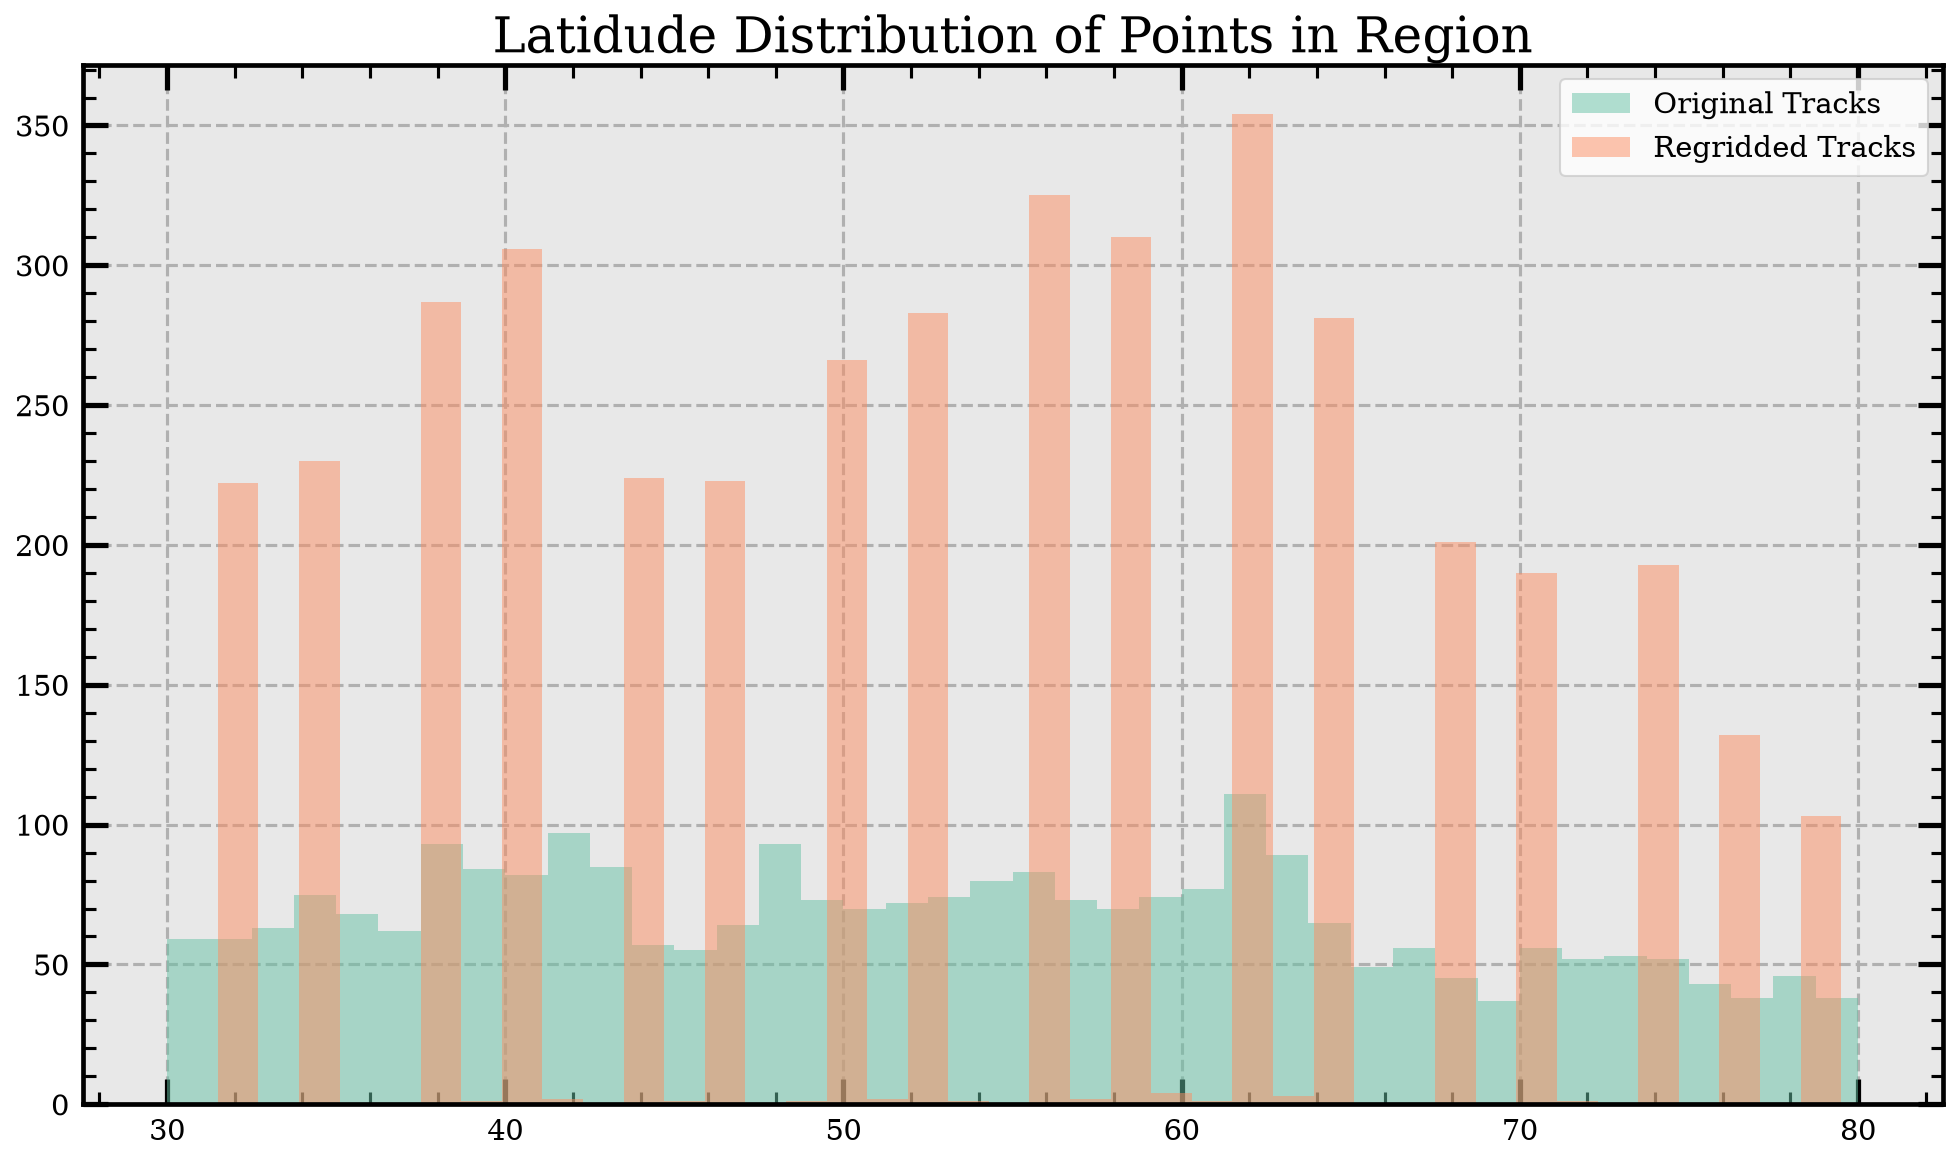

In [100]:
plt.hist(points_0_25['lat'][points_0_25['in_region']==True], bins=40, alpha=0.5, label='Original Tracks')
plt.hist(points_3['lat'][points_3['in_region']==True], bins=40, alpha=0.5, label='Regridded Tracks')
plt.title('Latidude Distribution of Points in Region')
plt.legend()

In [101]:
comp_3, matches_df_3 = val.compare_to_validation(tracks_0_25, tracks_3, matching = 'global_assignment', max_mean_separation_deg = 2.0, min_overlap_fraction=0.6, variable='vo')
comp_0_5, matches_df_0_5 = val.compare_to_validation(tracks_0_25, tracks_0_5, matching = 'global_assignment', max_mean_separation_deg = 2.0, min_overlap_fraction=0.6, variable='vo')

In [102]:
def results_df(tracks, comp):
    name = pd.Series({
        'Number of regridded': len(tracks),
        'Number of original tracks': len(tracks_0_25),
        'Number of matched tracks': comp.tp,
        'Number of missed tracks': comp.fn,
        'Number of extra tracks': comp.fp,
        'F1 score': comp.f1,
        'Precision': comp.precision,
        'Recall': comp.recall,
    })
    return name


In [103]:
results_df_0_5 = results_df(tracks_0_5, comp_0_5)
results_df_3 = results_df(tracks_3, comp_3)

In [104]:
results_df_3

Number of regridded          168.000000
Number of original tracks    129.000000
Number of matched tracks      51.000000
Number of missed tracks       78.000000
Number of extra tracks       117.000000
F1 score                       0.343434
Precision                      0.303571
Recall                         0.395349
dtype: float64

((0.4, 0.7607843137254902, 0.6470588235294118),
 (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
 (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
 (0.9058823529411765, 0.5411764705882353, 0.7647058823529411),
 (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
 (1.0, 0.8509803921568627, 0.1843137254901961),
 (0.8980392156862745, 0.7686274509803922, 0.5803921568627451),
 (0.7019607843137254, 0.7019607843137254, 0.7019607843137254))

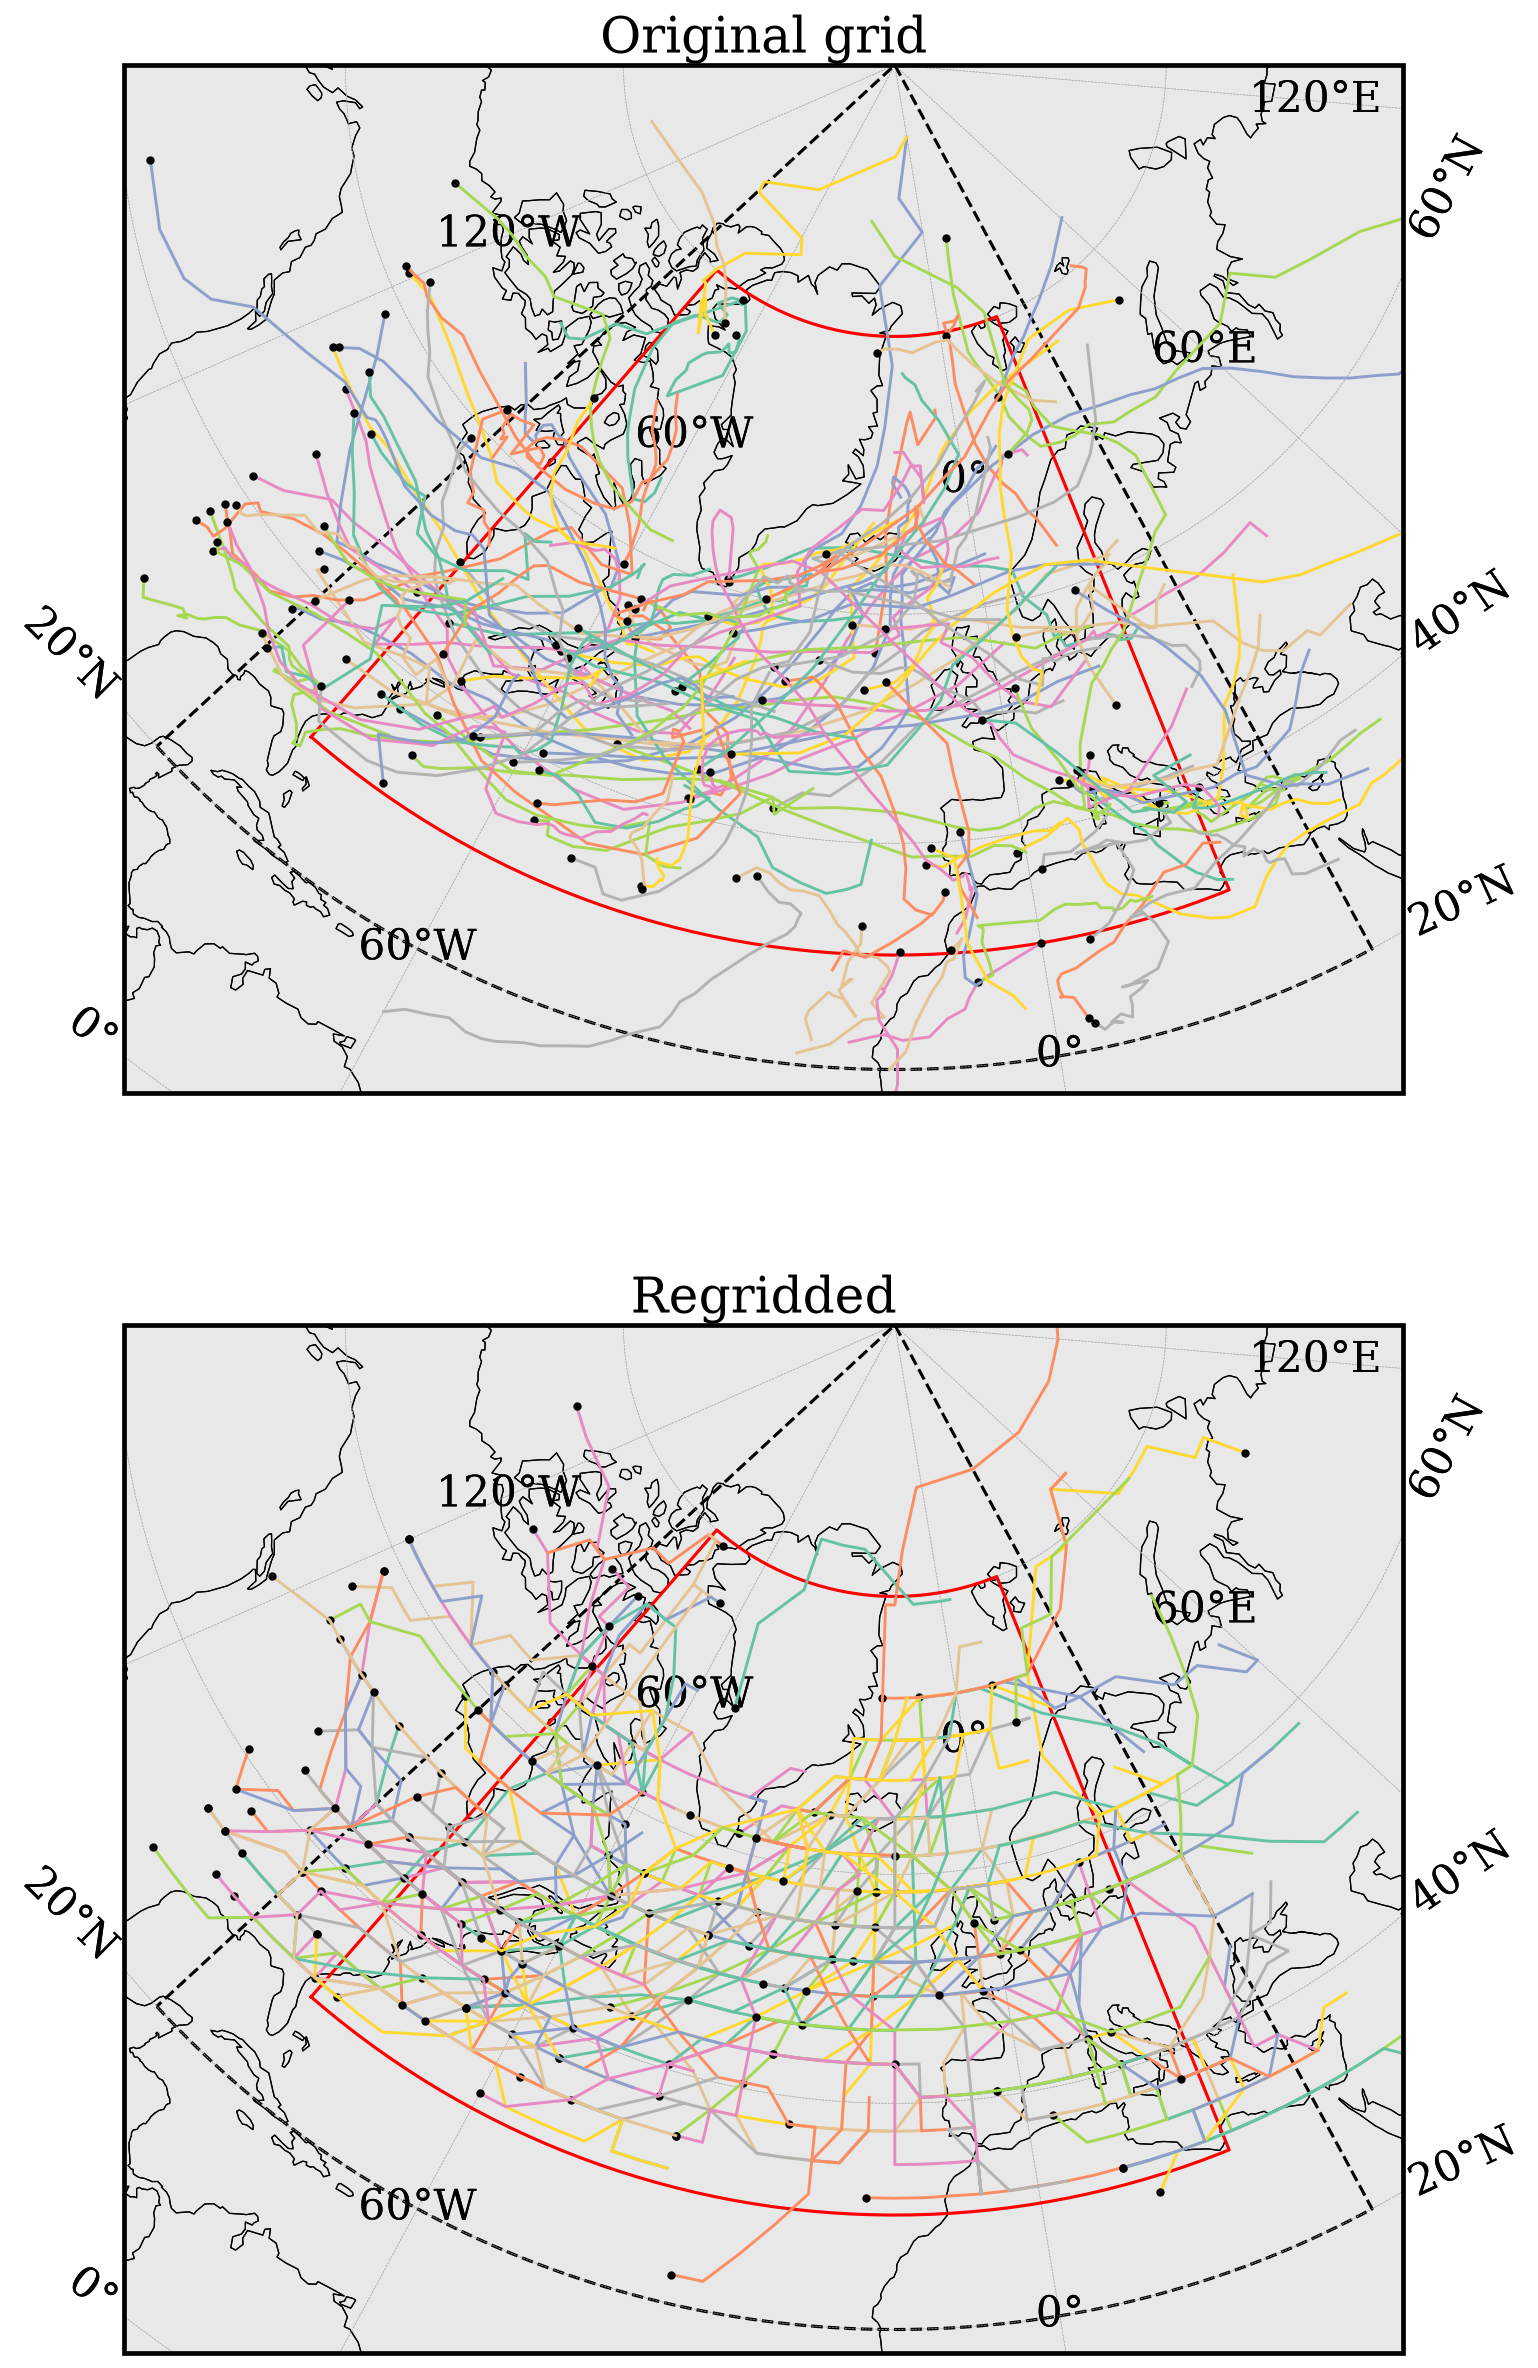

In [105]:


proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)
pc = ccrs.PlateCarree()
fig, axes = plt.subplots(2,1,figsize=(11, 20), subplot_kw={"projection": proj})


for box, style in ((DOMAIN, dict(color="k", linestyle="--")), (REGION, dict(color="red"))):
    # densify the edges so they follow parallels/meridians in the projection
    lo = np.linspace(box[0], box[1], 100)
    la = np.linspace(box[2], box[3], 100)
    xs = np.concatenate([lo, np.full(100, box[1]), lo[::-1], np.full(100, box[0])])
    ys = np.concatenate([np.full(100, box[2]), la, np.full(100, box[3]), la[::-1]])
    for ax in axes:
        ax.set_extent([DOMAIN[0] - 2, DOMAIN[1] + 2, DOMAIN[2] - 2, DOMAIN[3]], crs=pc)
        ax.coastlines(linewidth=0.6)
        ax.gridlines(draw_labels=True, linewidth=0.3)
        ax.plot(xs, ys, lw=1.5, transform=pc, **style)
for tr in tracks_0_25:
    kept = True
    if kept:
        axes[0].plot(tr.lons, tr.lats, "-", lw=1.4, transform=pc)
        axes[0].plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        axes[0].set_title('Original grid')
for track in tracks_3:
    kept = True
    if kept:
        axes[1].plot(track.lons, track.lats, "-", lw=1.4, transform=pc)
        axes[1].plot(track.lons[0], track.lats[0], "k.", ms=6, transform=pc)
        axes[1].set_title('Regridded')


setup_plotting()

#vmax = float(abs(vo).max())               # symmetric limits so white = 0

#fig, ax = geo_map(nrows=2)                # sized to fit, constrained layout
#for a, da, title in zip(ax, [tracks_0_25, tracks_3], ["0.25° grid", "0.75° grid"]):
#    im = da.plot(ax=a, transform=ccrs.PlateCarree())
#    a.set_title(title)

#add_colorbar(im, ax, label=r"Vorticity ($10^{-5}$ s$^{-1}$)",
#             location="bottom", labelsize=14)

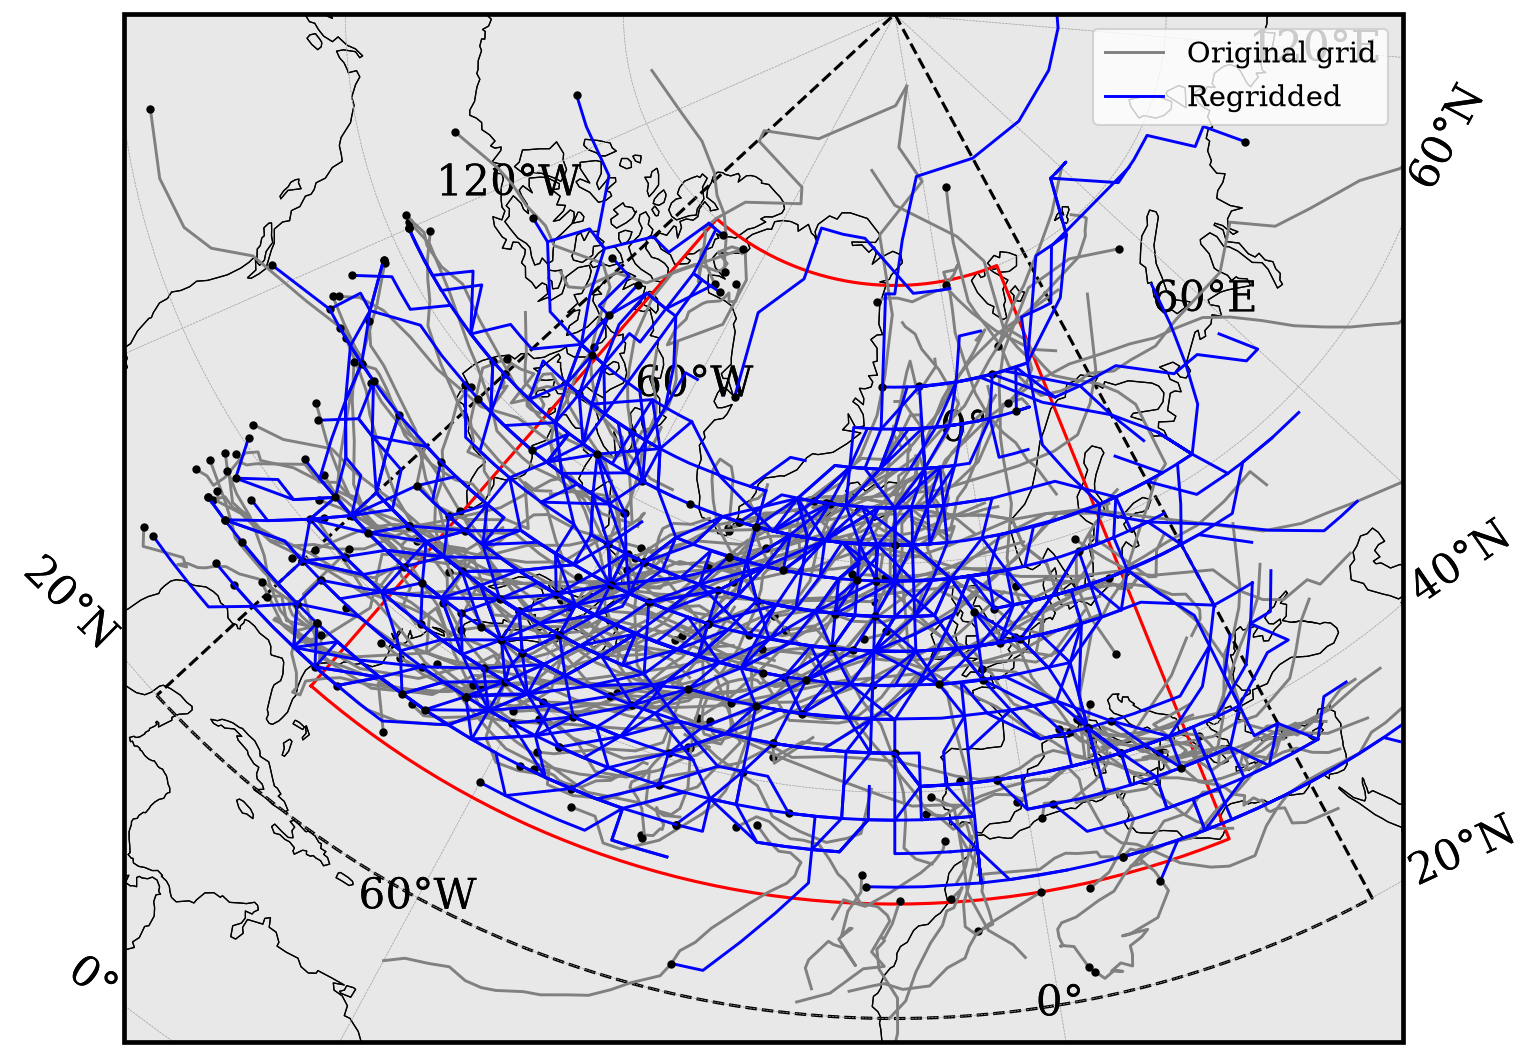

In [106]:


proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)
pc = ccrs.PlateCarree()
fig, axes = plt.subplots(figsize=(11, 20), subplot_kw={"projection": proj})


for box, style in ((DOMAIN, dict(color="k", linestyle="--")), (REGION, dict(color="red"))):
    # densify the edges so they follow parallels/meridians in the projection
    lo = np.linspace(box[0], box[1], 100)
    la = np.linspace(box[2], box[3], 100)
    xs = np.concatenate([lo, np.full(100, box[1]), lo[::-1], np.full(100, box[0])])
    ys = np.concatenate([np.full(100, box[2]), la, np.full(100, box[3]), la[::-1]])
    
    axes.set_extent([DOMAIN[0] - 2, DOMAIN[1] + 2, DOMAIN[2] - 2, DOMAIN[3]], crs=pc)
    axes.coastlines(linewidth=0.6)
    axes.gridlines(draw_labels=True, linewidth=0.3)
    axes.plot(xs, ys, lw=1.5, transform=pc, **style)

for i, tr in enumerate(tracks_0_25):
    kept = True
    if i == 0:
        axes.plot(tr.lons, tr.lats, "-", lw=1.4, color='grey', transform=pc, label='Original grid')
    if kept:
        axes.plot(tr.lons, tr.lats, "-", lw=1.4, color='grey', transform=pc)
        axes.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
    
       
for i, track in enumerate(tracks_3):
    kept = True
    if i == 0:
        axes.plot(track.lons, track.lats, "-", lw=1.4, color= 'blue', transform=pc, label= 'Regridded')
    if kept:
        axes.plot(track.lons, track.lats, "-", lw=1.4, color= 'blue', transform=pc)
        axes.plot(track.lons[0], track.lats[0], "k.", ms=6, transform=pc)

plt.legend()
        



<>:5: SyntaxWarning: invalid escape sequence '\c'
<>:6: SyntaxWarning: invalid escape sequence '\c'
<>:5: SyntaxWarning: invalid escape sequence '\c'
<>:6: SyntaxWarning: invalid escape sequence '\c'
/var/folders/bp/h0lnb5j91bn1mykh3m6j0dx00000gn/T/ipykernel_37233/3878245214.py:5: SyntaxWarning: invalid escape sequence '\c'
  plt.hist(tracks_3.lats,    bins=bins_lat-1.5, alpha=0.5, label='3$^\circ$ resolution', color='slateblue', edgecolor='k')
/var/folders/bp/h0lnb5j91bn1mykh3m6j0dx00000gn/T/ipykernel_37233/3878245214.py:6: SyntaxWarning: invalid escape sequence '\c'
  plt.hist(tracks_0_25.lats, bins=bins_lat-1.5, alpha=0.5, label='0.25$^\circ$ resolution', color='grey', edgecolor='k')


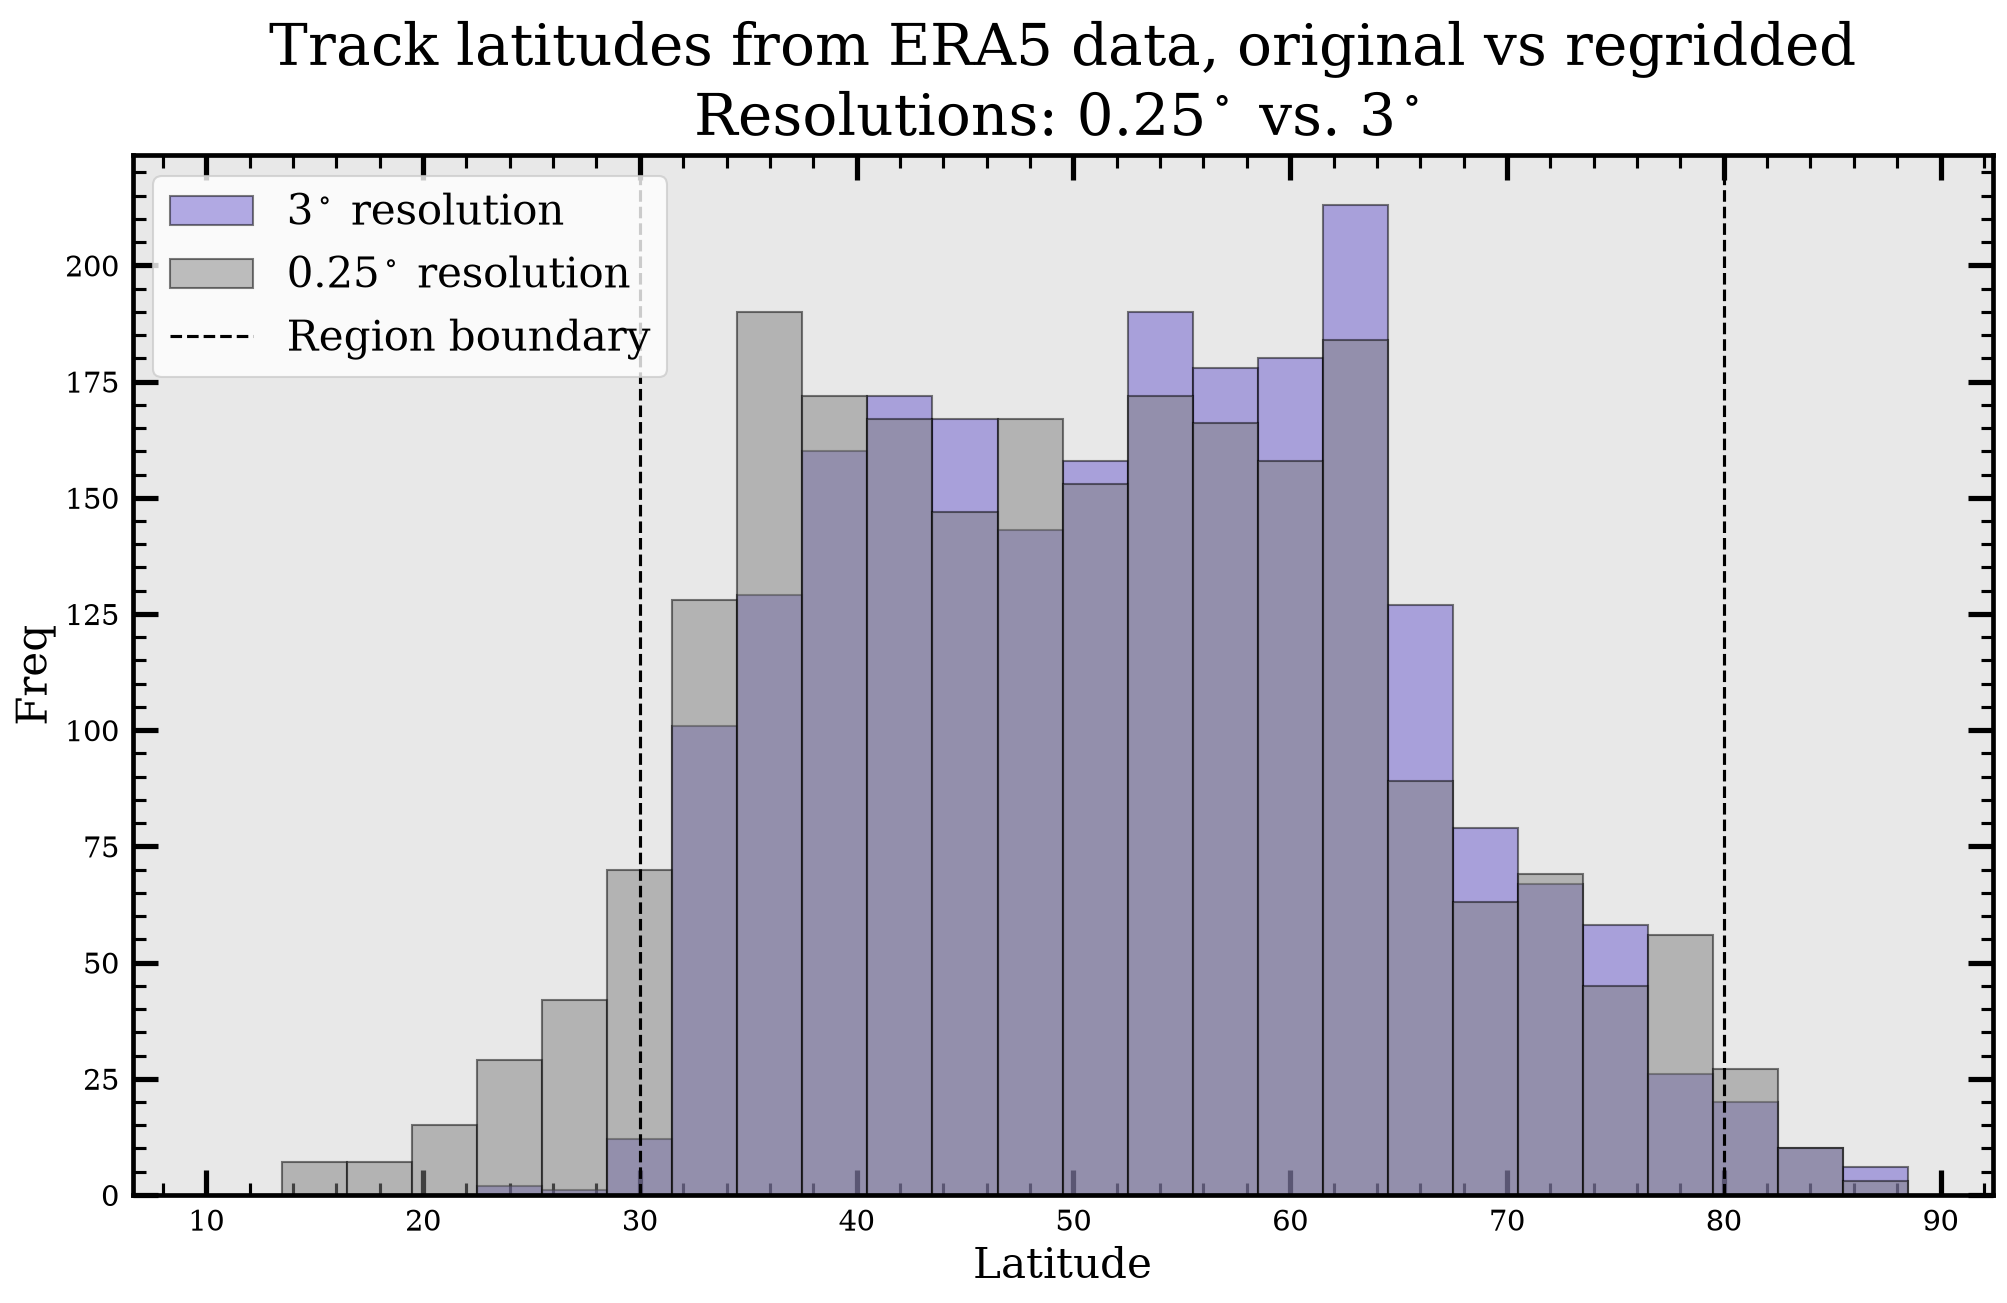

In [181]:
lat_min = np.floor(min(np.min(tracks_3.lats), np.min(tracks_0_25.lats)) / 3) * 3
lat_max = np.ceil(max(np.max(tracks_3.lats), np.max(tracks_0_25.lats)) / 3) * 3
bins_lat = np.arange(lat_min, lat_max + 3, 3)

plt.hist(tracks_3.lats,    bins=bins_lat-1.5, alpha=0.5, label='3$^\circ$ resolution', color='slateblue', edgecolor='k')
plt.hist(tracks_0_25.lats, bins=bins_lat-1.5, alpha=0.5, label='0.25$^\circ$ resolution', color='grey', edgecolor='k')
plt.axvline(x=REGION[2], color='k', linestyle='--', label='Region boundary')
plt.axvline(x=REGION[3], color='k', linestyle='--')
plt.grid(False)
plt.xlabel('Latitude', fontsize=20)
plt.ylabel('Freq')
plt.title(r'Track latitudes from ERA5 data, original vs regridded' "\n" r'Resolutions: 0.25$^\circ$ vs. 3$^\circ$', fontsize=28)
plt.legend(fontsize=20, loc= 'upper left')

Text(0.5, 1.0, 'Track longitudes from ERA5 data, original vs regridded\nResolutions: $0.25^\\circ$ vs. $3^\\circ$')

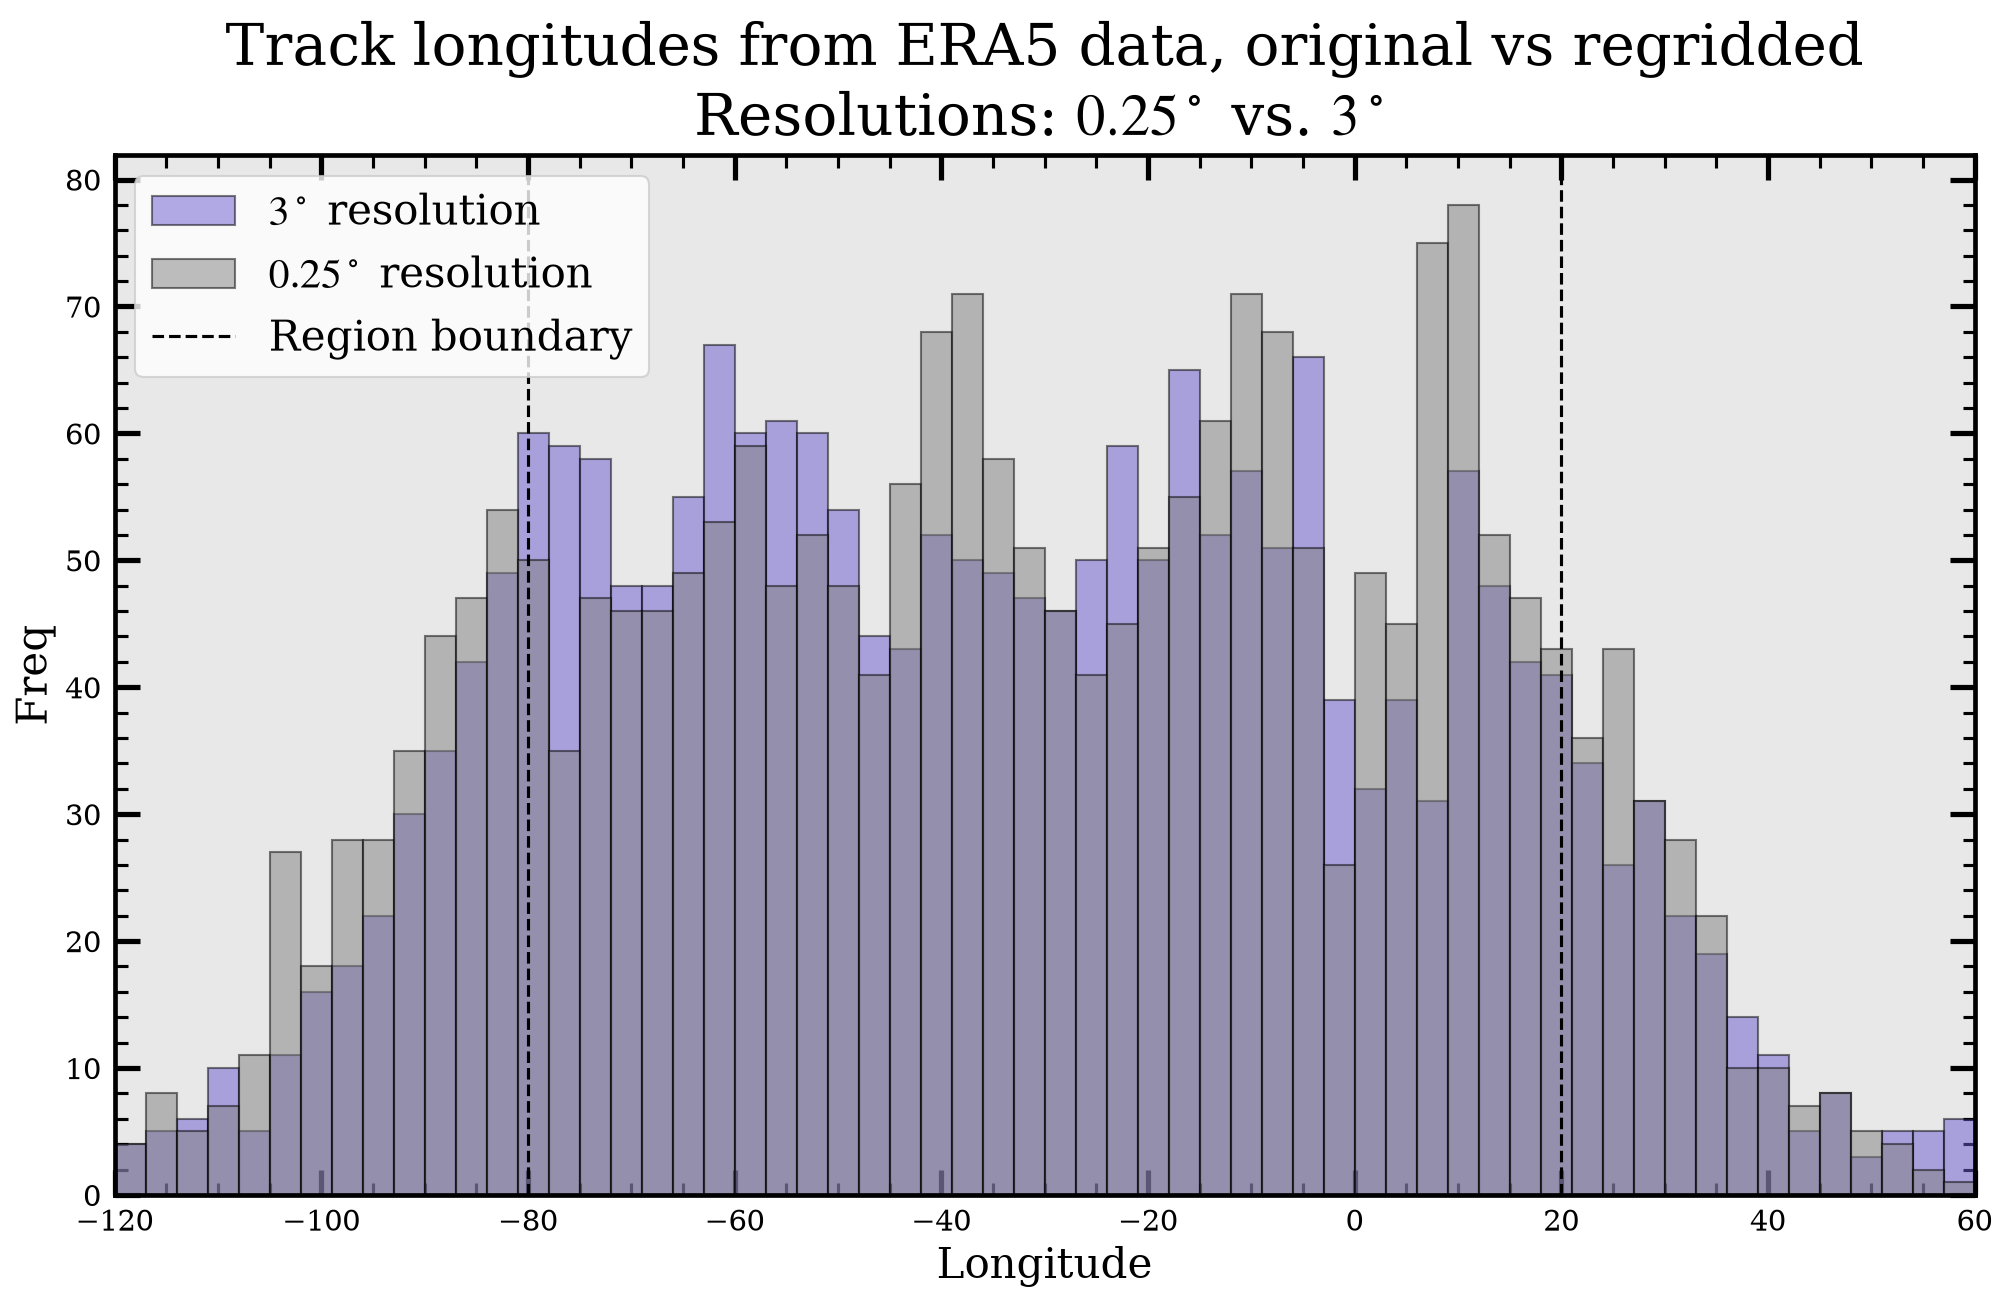

In [154]:
lon_min = np.floor(min(np.min(tracks_3.lons), np.min(tracks_0_25.lons)) / 3) * 3
lon_max = np.ceil(max(np.max(tracks_3.lons), np.max(tracks_0_25.lons)) / 3) * 3
bins_lon = np.arange(lon_min, lon_max + 3, 3)

plt.hist(tracks_3.lons,    bins=bins_lon, alpha=0.5, label=r'$3^\circ$ resolution',     color='slateblue', edgecolor='k')
plt.hist(tracks_0_25.lons, bins=bins_lon, alpha=0.5, label=r'$0.25^\circ$ resolution', color='grey', edgecolor= 'k')
plt.axvline(x=REGION[0], color='black', linestyle='--', label='Region boundary')
plt.axvline(x=REGION[1], color='black', linestyle='--')
plt.xlim(REGION[0]-40, REGION[1]+40)

plt.grid(False)
plt.xlabel('Longitude', fontsize = 20)
plt.ylabel('Freq')
plt.legend(fontsize=20)
plt.title(r'Track longitudes from ERA5 data, original vs regridded' "\n" r'Resolutions: $0.25^\circ$ vs. $3^\circ$', fontsize=28)

In [143]:
vo_3 = tracks_3.variables['vo']*1e5
vo_0_25 = tracks_0_25.variables['vo']*1e5

<>:20: SyntaxWarning: invalid escape sequence '\c'
<>:21: SyntaxWarning: invalid escape sequence '\c'
<>:20: SyntaxWarning: invalid escape sequence '\c'
<>:21: SyntaxWarning: invalid escape sequence '\c'
/var/folders/bp/h0lnb5j91bn1mykh3m6j0dx00000gn/T/ipykernel_37233/3425433344.py:20: SyntaxWarning: invalid escape sequence '\c'
  plt.axvline(x= med_3, color='slateblue', linestyle='-', label='Median 3$^\circ$' f': {med_3:.2f}', lw=1.5)
/var/folders/bp/h0lnb5j91bn1mykh3m6j0dx00000gn/T/ipykernel_37233/3425433344.py:21: SyntaxWarning: invalid escape sequence '\c'
  plt.axvline(x= med_0_25, color='grey', linestyle='-', label='Median 0.25$^\circ$' f': {med_0_25:.2f}', lw=1.5)


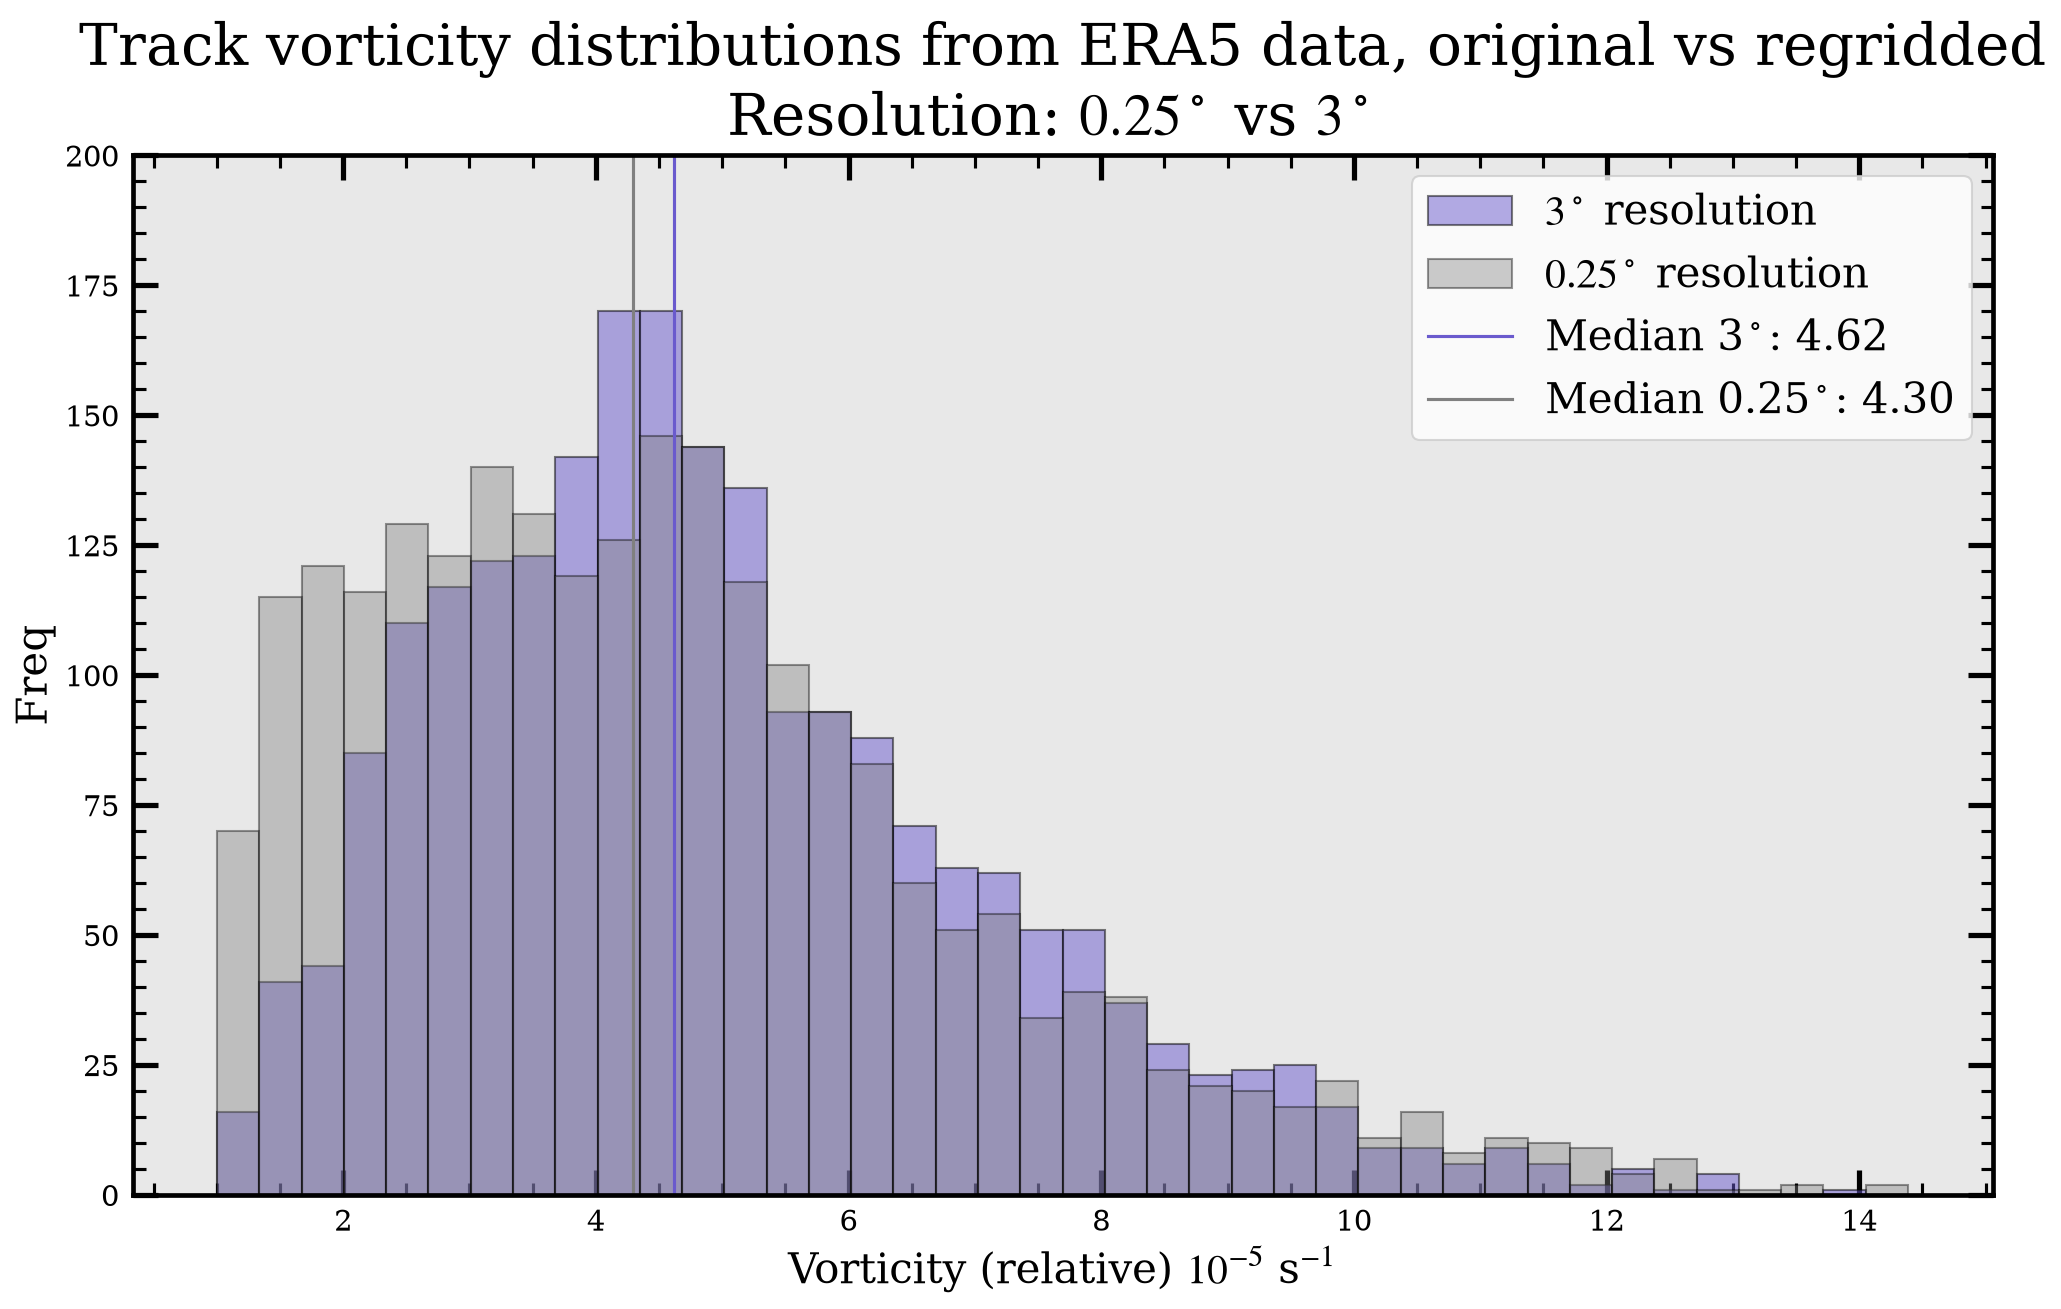

In [178]:
vo_3_flat    = np.ravel(vo_3)
vo_0_25_flat = np.ravel(vo_0_25)
all_vo = np.concatenate([vo_3_flat, vo_0_25_flat])

med_3    = np.median(tracks_3.variables['vo'] * 1e5)
med_0_25 = np.median(tracks_0_25.variables['vo'] * 1e5)

# Shared bin edges so both datasets are binned identically
bins_full = np.linspace(all_vo.min(), all_vo.max(), 41)

tail_q = 90                                   # tail starts at this percentile
tail_start = np.percentile(all_vo, tail_q)
bins_tail = np.linspace(tail_start, all_vo.max(), 31)

plt.hist(vo_3_flat,    bins=bins_full, alpha=0.5, label=r'$3^\circ$ resolution',     color='slateblue', edgecolor='k')
plt.hist(vo_0_25_flat, bins=bins_full, alpha=0.4, label=r'$0.25^\circ$ resolution', color='grey', edgecolor='k')
#plt.axvline(tail_start, color='k', ls='--', lw=1)
#plt.text(0.65, 0.5, f'Median 3$^\circ$: {med_3:.2f}', transform=plt.gca().transAxes, fontsize=20, verticalalignment='top', color='k')
#plt.text(0.65, 0.6, f'Median 0.25$^\circ$: {med_0_25:.2f}', transform=plt.gca().transAxes, fontsize=20, verticalalignment='top', color='k')
plt.axvline(x= med_3, color='slateblue', linestyle='-', label='Median 3$^\circ$' f': {med_3:.2f}', lw=1.5)
plt.axvline(x= med_0_25, color='grey', linestyle='-', label='Median 0.25$^\circ$' f': {med_0_25:.2f}', lw=1.5)
plt.xlabel('Vorticity (relative) $10^{-5}$ s$^{-1}$', fontsize= 20)
plt.ylabel('Freq')
plt.ylim(0, 200)
plt.title(r'Track vorticity distributions from ERA5 data, original vs regridded' "\n" r'Resolution: $0.25^\circ$ vs $3^\circ$ ', fontsize=28)
plt.legend(fontsize=20)
plt.grid(False)

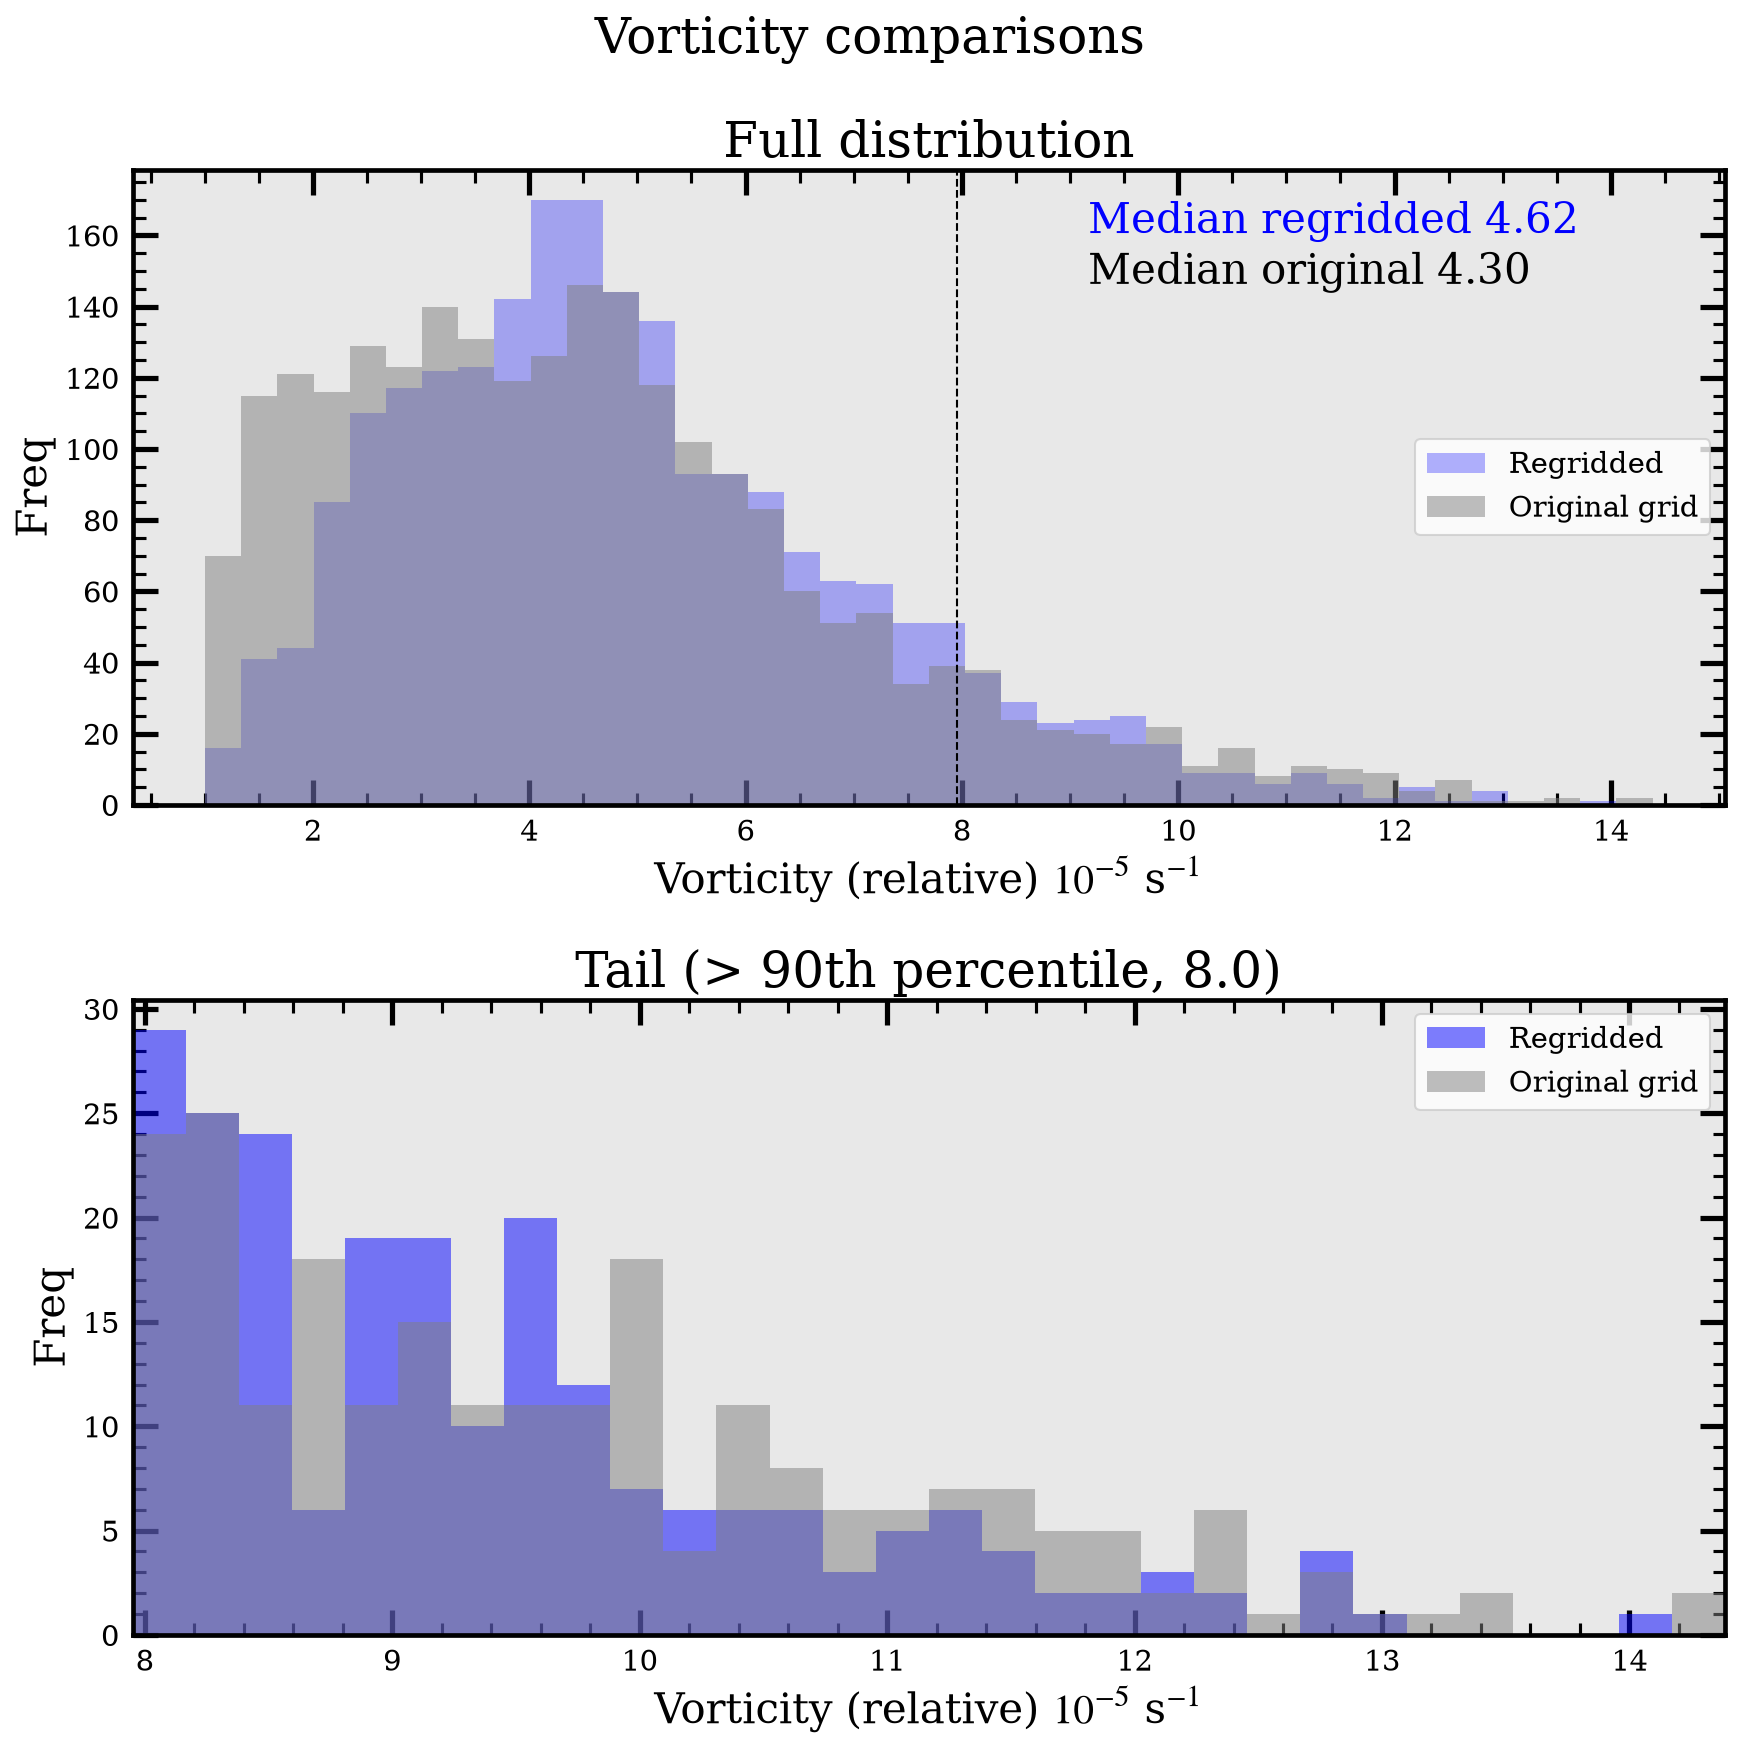

In [111]:
vo_3_flat    = np.ravel(vo_3)
vo_0_25_flat = np.ravel(vo_0_25)
all_vo = np.concatenate([vo_3_flat, vo_0_25_flat])

med_3    = np.median(tracks_3.variables['vo'] * 1e5)
med_0_25 = np.median(tracks_0_25.variables['vo'] * 1e5)

# Shared bin edges so both datasets are binned identically
bins_full = np.linspace(all_vo.min(), all_vo.max(), 41)

tail_q = 90                                   # tail starts at this percentile
tail_start = np.percentile(all_vo, tail_q)
bins_tail = np.linspace(tail_start, all_vo.max(), 31)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12))

# Full distribution
ax1.hist(vo_3_flat,    bins=bins_full, alpha=0.3, label='Regridded',     color='blue')
ax1.hist(vo_0_25_flat, bins=bins_full, alpha=0.5, label='Original grid', color='grey')
ax1.axvline(tail_start, color='k', ls='--', lw=1)
ax1.text(0.60, 0.90, f'Median regridded {med_3:.2f}', color='blue', transform=ax1.transAxes)
ax1.text(0.60, 0.82, f'Median original {med_0_25:.2f}', transform=ax1.transAxes)
ax1.set_xlabel('Vorticity (relative) $10^{-5}$ s$^{-1}$')
ax1.set_ylabel('Freq')
ax1.set_title('Full distribution')
ax1.legend(loc='center right')
ax1.grid(False)

# Zoom on the tail (finer bins over the tail range only)
ax2.hist(vo_3_flat,    bins=bins_tail, alpha=0.5, label='Regridded',     color='blue')
ax2.hist(vo_0_25_flat, bins=bins_tail, alpha=0.5, label='Original grid', color='grey')
ax2.set_xlim(tail_start, all_vo.max())
ax2.set_xlabel('Vorticity (relative) $10^{-5}$ s$^{-1}$')
ax2.set_ylabel('Freq')
ax2.set_title(f'Tail (> {tail_q}th percentile, {tail_start:.1f})')
ax2.grid(False)
ax2.legend()

fig.suptitle('Vorticity comparisons')
fig.tight_layout()
plt.show()


In [112]:
vort_relative_diff = (np.mean(tracks_3.variables['vo']) - np.mean(tracks_0_25.variables['vo'])) / np.mean(tracks_0_25.variables['vo'])

In [113]:
print(vort_relative_diff)

0.0757223971175759
